In [1]:
# Install required libraries (run once in Jupyter)
%pip install tensorflow numpy pandas matplotlib scikit-learn

In [2]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [4]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

In [5]:
# Load CSV files
telemetry = pd.read_csv("PdM_telemetry.csv")
failures = pd.read_csv("PdM_failures.csv")

In [6]:
# Merge telemetry and failure records
data = pd.merge(
    telemetry,
    failures[["datetime", "machineID"]],
    on=["datetime", "machineID"],
    how="left",
    indicator=True
)

In [7]:

# Create anomaly label
data["is_anomaly"] = (data["_merge"] == "both").astype(int)

In [8]:
# Select 4 numerical features
features = ["volt", "rotate", "pressure", "vibration"]

In [9]:
# Separate normal and anomaly records
normal = data[data["is_anomaly"] == 0].copy()
anomaly = data[data["is_anomaly"] == 1].copy()

In [10]:
print("Normal records:", normal.shape)
print("Anomaly records:", anomaly.shape)

Normal records: (875381, 8)
Anomaly records: (761, 8)


In [11]:
# Split normal records into training and validation
train_normal, test_normal = train_test_split(
    normal,
    test_size=0.2,
    random_state=42
)

In [12]:
# Standardize the features
scaler = StandardScaler()

In [13]:
X_train = scaler.fit_transform(train_normal[features])
X_normal_test = scaler.transform(test_normal[features])
X_anomaly = scaler.transform(anomaly[features])

In [14]:
# Create Autoencoder input layer
input_layer = Input(shape=(4,))

In [15]:
# Encoder
encoder = Dense(2, activation="relu")(input_layer)

In [16]:
# Decoder
decoder = Dense(4)(encoder)

In [17]:
# Create Autoencoder model
model = Model(inputs=input_layer, outputs=decoder)

In [18]:
# Compile model
model.compile(optimizer="adam", loss="mse")

In [19]:
# Train using only normal data
model.fit(
    X_train,
    X_train,
    epochs=20,
    batch_size=256,
    validation_split=0.1
)

Epoch 1/20
2463/2463 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 0.7202 - val_loss: 0.5307
Epoch 2/20
2463/2463 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 0.5093 - val_loss: 0.5009
Epoch 3/20
2463/2463 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 0.5012 - val_loss: 0.4993
Epoch 4/20
2463/2463 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 0.5004 - val_loss: 0.4989
Epoch 5/20
2463/2463 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 0.5001 - val_loss: 0.4990
Epoch 6/20
2463/2463 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 0.5000 - val_loss: 0.4988
Epoch 7/20
2463/2463 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.4999 - val_loss: 0.4987
Epoch 8/20
2463/2463 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.4999 - val_loss: 0.4989
Epoch 9/20
2463/2463 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 0.4999 - val_loss: 0.4988
Epoch 10/20
2463/2463 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 0.4998 - val_loss: 0.4989
Epoch 11/20
2463/2463 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 0.4998 - val_loss: 0.4989
Epoch 12/20
2463/2463 ━━━━━━━━

In [20]:
# Combine normal and anomaly test data
test = np.concatenate((X_normal_test, X_anomaly))

In [21]:
# Create actual labels
y_actual = np.concatenate((
    np.zeros(len(X_normal_test)),
    np.ones(len(X_anomaly))
))

In [22]:
# Reconstruct test data
predicted = model.predict(test)

5495/5495 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step


In [23]:
# Calculate reconstruction error
error = np.mean((test - predicted)**2, axis=1)

In [24]:
# Calculate threshold using normal validation data
threshold = np.percentile(
    np.mean((X_normal_test - model.predict(X_normal_test))**2, axis=1),
    95
)

5472/5472 ━━━━━━━━━━━━━━━━━━━━ 6s 1ms/step


In [25]:
# Detect anomalies
result = error > threshold

In [26]:
# Print results
print("Threshold:", threshold)
print("First 10 reconstruction errors:")
print(error[:10])

Threshold: 1.5344727511935257
First 10 reconstruction errors:
[0.05600545 0.1135408  0.12885365 0.01866922 0.47890394 0.39280818
 1.07562187 0.23854686 0.31405212 1.24555728]


In [27]:
print("Anomalies detected:", np.sum(result))

Anomalies detected: 8874


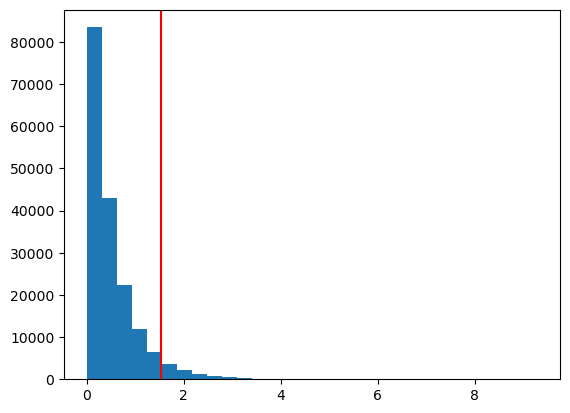

In [28]:
# Display histogram
plt.hist(error, bins=30)

# Draw threshold line
plt.axvline(
    threshold,
    color="red",
    label="Threshold"
)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_16540\1712167770.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


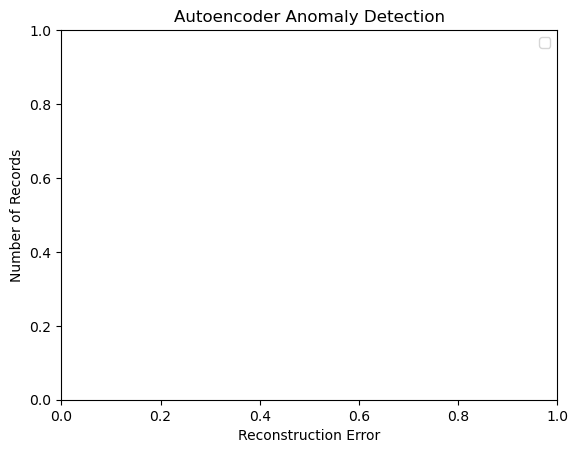

In [29]:
plt.title("Autoencoder Anomaly Detection")
plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Records")

plt.legend()
plt.show()